# Map-based simulation for time-dependent random pointing with HWP

Following `abs_pointing_offset.ipynb`, we load cross-links, generate a beam-smoothed
CMB, build `SignalFields`, solve the HWP 3x3 system, inspect input/output/residual
maps, and use the residual BB spectrum to estimate the bias $\Delta r$ with
`sbm.forecast`. We finish with the likelihood curve and the inferred $r$.

The two orthogonal detectors share independent per-hit Cartesian displacements
$\Delta x,\Delta y\sim\mathcal N(0,\sigma^2)$, so
$\zeta=0$ and $\bar\zeta=2(\Delta y+i\Delta x)$.
The ideal temperature is zero and there is no temperature-gradient leakage.


In [1]:
%matplotlib inline

from io import BytesIO
from IPython.display import Image, display
from pathlib import Path
import numpy as np
import healpy as hp
import matplotlib.pyplot as plt
import sbm
from sbm import ScanFields, SignalFields

repo = Path.cwd()
if not (repo / "tests").is_dir():
    repo = repo.parent


## 1. Load cross-links

This executable example repeats the 12 scan-angle distributions in the bundled
regression fixture across an **nside=64** HEALPix sky. Each pixel has 512 hits.
This produces an illustrative full-sky scan with the required harmonics, enabling
$2\leq\ell\leq191$ likelihood evaluation without an external scan database.
Its $\Delta r$ describes this demonstration scan, rather than a particular survey.
For a survey forecast, replace this cell with `ScanFields.load_det(...)` using
cross-links generated for that observation.

The scan needs all pairwise sum and difference harmonics of
`(3,-4), (-1,4), (1,0), (5,-8), (-3,8)`. Both covariance and pseudo-covariance
are required because the Cartesian offsets are real Gaussian variables.


In [2]:
with np.load(repo / "tests/reference/random_pointing.npz") as data:
    reference = {key: data[key] for key in data.files}

nside = 64
scan_field = ScanFields()
scan_field.nside = nside
scan_field.npix = hp.nside2npix(nside)
# Repeat the fixture's scan distributions; each remains a valid hit average.
pixel_template = np.arange(scan_field.npix) % len(reference["hitmap"])
scan_field.hitmap = reference["hitmap"][pixel_template].copy()
scan_field.spins_n = np.arange(11)
scan_field.spins_m = np.arange(-16, 17)
scan_field.h = np.zeros((scan_field.npix, 33, 11), dtype=complex)
for (n, m), values in zip(reference["spins"], reference["harmonics"]):
    scan_field.h[:, m + 16, n] = values[pixel_template]
    if n == 0:
        scan_field.h[:, -m + 16, n] = values[pixel_template].conj()
print(f"nside={nside}, Npix={scan_field.npix:,}, hits/pixel={scan_field.hitmap[0]}")


nside=64, Npix=49,152, hits/pixel=512


## 2. Input CMB, beam smoothing and polarization derivatives

We generate a CMB with input $r=0$, smooth it with a 1 degree Gaussian beam,
and calculate the polarization derivatives in the same convention as the
absolute-pointing tutorial. The co-pointed pair model fixes ideal intensity to
zero, so only Q and U from this CMB enter the random-pointing calculation.
The beam window is retained for the subsequent residual BB deconvolution.


In [3]:
r_input = 0.0
lmax = 3 * nside - 1
fwhm = np.deg2rad(1.0)
fiducial_map = sbm.generate_cmb(nside, r=r_input, cmb_seed=12345)
input_map = hp.smoothing(fiducial_map, fwhm=fwhm, lmax=lmax)
input_map[0] = 0.0
bl = hp.gauss_beam(fwhm, lmax=lmax, pol=True)

P = input_map[1] + 1j * input_map[2]
dQ = hp.alm2map_der1(hp.map2alm(input_map[1], lmax=lmax), nside, lmax=lmax)
dU = hp.alm2map_der1(hp.map2alm(input_map[2], lmax=lmax), nside, lmax=lmax)
eth_P = dQ[2] + dU[1] - 1j * (dQ[1] - dU[2])
o_eth_P = dQ[2] - dU[1] + 1j * (dQ[1] + dU[2])


## 3. Set the pointing width and build signal fields

`sigma_rad` is the standard deviation of **each Cartesian component per hit**,
not the RMS radial displacement (which is $\sqrt{2}\sigma$).
For a per-axis NEPointing in arcmin $\sqrt{\mathrm{s}}$,
`sigma_rad = np.deg2rad(NEPointing * np.sqrt(sampling_rate_hz) / 60)`.
A fixed seed replays the same realization without changing NumPy's global RNG.


In [4]:
sigma_arcmin = 1.0
sigma_rad = np.deg2rad(sigma_arcmin / 60.0)
mdim = 3
signal_field = SignalFields.random_pointing_field(
    scan_field, mdim, sigma_rad, P, eth_P, o_eth_P, seed=23000001
)


## 4. Solve the linear system

As in the absolute-pointing tutorial, pass the signal fields to the existing
`ScanFields.map_make` solver. Define the residual as input minus output; this
sign does not change its power spectrum.


In [5]:
output_map = scan_field.map_make(signal_field, show_eq=True)
residual = input_map - output_map
p_rms = np.sqrt(np.mean(residual[1]**2 + residual[2]**2))
print(f"Polarization residual RMS = {p_rms:.6e} microK")


<IPython.core.display.Math object>

Polarization residual RMS = 1.306961e-03 microK


## 5. Input, output and residual maps

The first row shows the ideal I/Q/U sky, the second the reconstructed maps,
and the third their residuals. Use the same color limits for input and output
in each Stokes column. The residuals use their own scales so the much smaller
pointing contamination remains visible. Although ideal I is zero, the HWP
3x3 solution can contain a systematic intensity residual.


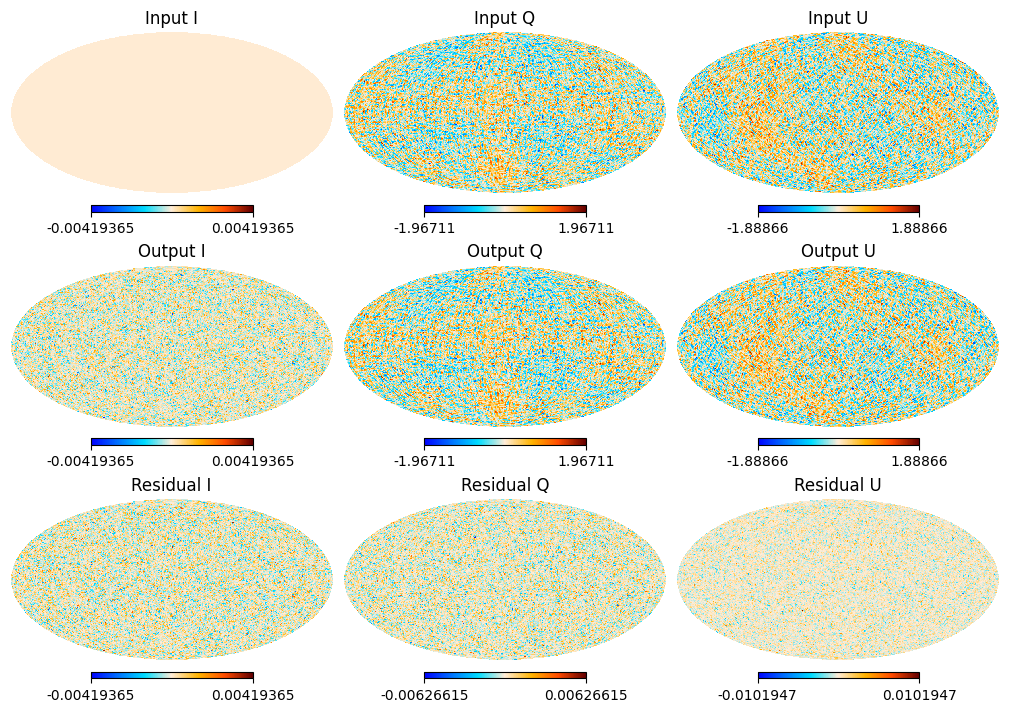

In [ ]:
cmap = sbm.get_cmap()
plot_figure = plt.figure(figsize=(10, 7))
for row, (maps, label) in enumerate(((input_map, "Input"), (output_map, "Output"), (residual, "Residual"))):
    for column, stokes in enumerate(("I", "Q", "U")):
        if row < 2:
            vmax = max(np.max(np.abs(input_map[column])), np.max(np.abs(output_map[column])))
        else:
            vmax = np.max(np.abs(residual[column]))
        vmax = max(float(vmax), 1e-12)
        hp.mollview(maps[column], sub=(3, 3, row * 3 + column + 1),
                    title=f"{label} {stokes}", cmap=cmap, min=-vmax, max=vmax)
                
# Emit PNG output explicitly, including when the kernel used Agg previously.
image_buffer = BytesIO()
plot_figure.savefig(image_buffer, format="png", dpi=100, bbox_inches="tight")
plt.close(plot_figure)
display(Image(data=image_buffer.getvalue()))


## 6. Residual BB power and beam deconvolution

Calculate the residual spectra and divide BB by the squared polarization beam
window. `sbm.forecast` compares this deconvolved spectrum with its unbeamed CMB
templates. We explicitly set monopole and dipole to zero, as required by
`forecast`. The lensing BB curve ($r=0$) and primordial tensor BB curve ($r=1$)
provide context for the residual. These plots use $C_\ell$, as in the existing
SBM tutorial.


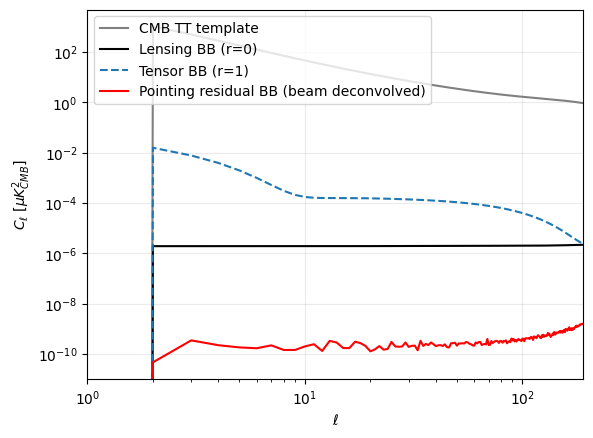

In [7]:
fiducial_cl = sbm.load_fiducial_cl(r_input, lmax=lmax)
tensor_cl = sbm.load_fiducial_cl(1.0, lmax=lmax) - fiducial_cl
res_cl = hp.anafast(residual, lmax=lmax, pol=True)
delta_cl = res_cl[2] / bl[:, 2]**2
delta_cl[:2] = 0.0
ell = np.arange(lmax + 1)

plot_figure = plt.figure(figsize=(6.4, 4.8))
plt.plot(ell[1:], fiducial_cl[0, 1:], color="gray", label="CMB TT template")
plt.plot(ell[1:], fiducial_cl[2, 1:], color="black", label="Lensing BB (r=0)")
plt.plot(ell[1:], tensor_cl[2, 1:], "--", label="Tensor BB (r=1)")
plt.plot(ell[1:], delta_cl[1:], color="red", label="Pointing residual BB (beam deconvolved)")
plt.xlabel(r"$\ell$")
plt.ylabel(r"$C_\ell\ [\mu K_{CMB}^2]$")
plt.xscale("log")
plt.xlim(1, lmax)
plt.yscale("log")
plt.grid(alpha=0.25)
plt.legend()
# Emit PNG output explicitly, including when the kernel used Agg previously.
image_buffer = BytesIO()
plot_figure.savefig(image_buffer, format="png", dpi=100, bbox_inches="tight")
plt.close(plot_figure)
display(Image(data=image_buffer.getvalue()))


## 7. Estimate the tensor-to-scalar ratio bias

Use the existing `sbm.forecast` with $2\leq\ell\leq191$, full-sky coverage and
its default zero-noise assumption, matching the absolute-pointing tutorial.
The fitted $\Delta r$ is the apparent primordial tensor amplitude contributed
by the residual BB spectrum. It is a systematic bias estimate for this scan
and realization, rather than an uncertainty on $r$.


In [8]:
lmax_likelihood = min(191, lmax)
forecast = sbm.forecast(delta_cl, lmax=lmax_likelihood, fsky=1.0)
delta_r = float(forecast["delta_r"])
assert np.isfinite(delta_r) and delta_r > 0
print(f"Likelihood multipoles: 2 <= ell <= {lmax_likelihood}")
print(f"Pointing-induced delta_r = {delta_r:.8e}")


Likelihood multipoles: 2 <= ell <= 191
Pointing-induced delta_r = 2.08506332e-07


## 8. Plot the likelihood

`forecast["likelihood"]` contains the **negative log-likelihood** evaluated on
its display grid. Convert it to a relative likelihood by subtracting its minimum
and exponentiating with a minus sign. This gives a curve peaking at one and
avoids numerical underflow from an arbitrary normalization. The vertical line
marks the fitted $\Delta r$.

The display grid is centered on the fitted bias by `forecast`; it is not a
confidence interval. With this small residual the relative likelihood varies
only slightly across that window, so the vertical axis is zoomed near one.


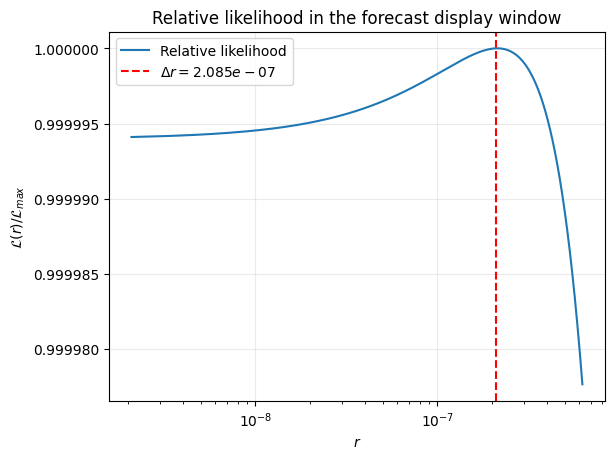

In [9]:
r_grid = forecast["grid_r"]
negative_log_likelihood = forecast["likelihood"]
relative_likelihood = np.exp(-(negative_log_likelihood - np.min(negative_log_likelihood)))
assert np.all(np.isfinite(relative_likelihood))

plot_figure = plt.figure(figsize=(6.4, 4.8))
plt.plot(r_grid, relative_likelihood, label="Relative likelihood")
plt.axvline(delta_r, color="red", linestyle="--", label=rf"$\Delta r = {delta_r:.3e}$")
plt.xlabel(r"$r$")
plt.ylabel(r"$\mathcal{L}(r) / \mathcal{L}_{max}$")
plt.xscale("log")
plt.ticklabel_format(axis="y", style="plain", useOffset=False)
plt.title("Relative likelihood in the forecast display window")
plt.grid(alpha=0.25)
plt.legend()
# Emit PNG output explicitly, including when the kernel used Agg previously.
image_buffer = BytesIO()
plot_figure.savefig(image_buffer, format="png", dpi=100, bbox_inches="tight")
plt.close(plot_figure)
display(Image(data=image_buffer.getvalue()))


## 9. Final inferred r

The input CMB has $r_{\mathrm{input}}=0$. Under the forecast assumptions the
pointing residual would be interpreted as $r_{\mathrm{apparent}}=\Delta r$.
We display the input, the systematic bias and their sum explicitly.


In [10]:
r_apparent = r_input + delta_r
print(f"Input tensor-to-scalar ratio:   r_input = {r_input:.1f}")
print(f"Random-pointing bias:          delta_r = {delta_r:.8e}")
print(f"Apparent tensor-to-scalar ratio:      r = {r_apparent:.8e}")


Input tensor-to-scalar ratio:   r_input = 0.0
Random-pointing bias:          delta_r = 2.08506332e-07
Apparent tensor-to-scalar ratio:      r = 2.08506332e-07


## Appendix: original implementation reference

The small regression fixture was evaluated independently with the original
Cartesian moment implementation. This check uses its own nside=1 scan and does
not replace the higher-resolution maps or forecast above. The test suite also
replays the previously saved nside=256 BB spectrum; see
`tests/reference/random_pointing.md` for provenance and the replay command.


In [11]:
reference_scan = ScanFields()
reference_scan.hitmap = reference["hitmap"].copy()
reference_scan.npix = len(reference_scan.hitmap)
reference_scan.nside = hp.npix2nside(reference_scan.npix)
reference_scan.spins_n = np.arange(11)
reference_scan.spins_m = np.arange(-16, 17)
reference_scan.h = np.zeros((reference_scan.npix, 33, 11), dtype=complex)
for (n, m), values in zip(reference["spins"], reference["harmonics"]):
    reference_scan.h[:, m + 16, n] = values
    if n == 0:
        reference_scan.h[:, -m + 16, n] = values.conj()
reference_field = SignalFields.random_pointing_field(
    reference_scan, 3, float(reference["sigma_rad"]), reference["P"],
    reference["eth_P"], reference["o_eth_P"], seed=int(reference["seed"])
)
np.testing.assert_allclose(reference_scan.map_make(reference_field),
                           reference["output_iqu"], rtol=1e-12, atol=1e-12)
print("Original implementation reference: passed")


Original implementation reference: passed


For exact TOD comparisons, pass `moments=(O_x, O_y)` instead of a seed. Each
array has shape `(npix, 5)` in the documented spin order and contains the
unnormalized displacement-weighted harmonic sums. Their amplitude is already
included, so `sigma_rad` is not applied again. Only the HWP 3x3 model is supported;
zero-hit pixels return zero output.
